In [170]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns  

In [171]:
df=pd.read_csv("HR_Attrition_Raw.csv")

In [172]:
df.sample(10)

,EmployeeID,Age,Department,SalaryBand,JobRole,Gender,YearsAtCompany,PerformanceScore,MonthlyIncome,Attrition
563,EMP0564,29.0,Sales,low,Analyst,Other,7.9,1.8,60585.53,No
986,EMP0987,28.0,Engineering,NaN,Analyst,Male,13.2,1.4,98218.68,No
270,EMP0271,40.0,Engineering,NaN,MANAGER,M,32.6,1.5,47994.77,No
962,EMP0963,47.0,hr,High,Engineer,male,27.4,3.4,136706.66,Yes
594,EMP0595,32.0,IT,MED,NaN,M,13.1,3.0,85520.49,No
7,EMP0008,32.0,hr,Low,MANAGER,Female,18.5,1.2,-1000,No
943,EMP0944,52.0,HR,NaN,Manager,Other,28.1,1.1,133504.15,No
385,EMP0386,44.0,NaN,HIGH,NaN,F,7.1,4.4,73915.66,No
746,EMP0747,38.0,HR,MED,Director,male,14.0,3.9,37114.97,No
254,EMP0255,33.0,IT,Low,analyst,male,34.9,1.7,-1000,No


In [173]:
df["SalaryBand"].unique()

array(['Medium', 'Very High', 'HIGH', 'High', nan, 'Low', 'Band-B', 'MED',
       'low', 'Band-A'], dtype=object)

In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   EmployeeID        1000 non-null   object 
 1   Age               1009 non-null   float64
 2   Department        932 non-null    object 
 3   SalaryBand        921 non-null    object 
 4   JobRole           930 non-null    object 
 5   Gender            939 non-null    object 
 6   YearsAtCompany    993 non-null    object 
 7   PerformanceScore  1004 non-null   float64
 8   MonthlyIncome     1008 non-null   object 
 9   Attrition         1023 non-null   object 
dtypes: float64(2), object(8)
memory usage: 80.6+ KB


In [175]:
df.describe()

,Age,PerformanceScore
count,1009.000000,1004.000000
mean,48.932607,4.229582
std,90.990348,10.928582
min,-5.000000,-1.000000
25%,31.000000,1.900000
50%,42.000000,3.100000
75%,51.000000,4.000000
max,999.000000,99.000000


In [176]:
df.isnull().sum()

EmployeeID           30
Age                  21
Department           98
SalaryBand          109
JobRole             100
Gender               91
YearsAtCompany       37
PerformanceScore     26
MonthlyIncome        22
Attrition             7
dtype: int64

In [177]:
df = df[df['EmployeeID'].notna()]

In [178]:
df["EmployeeID"].isnull().sum()


np.int64(0)

In [179]:
df["Age"].astype(int)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [180]:
df["Age"].unique()

array([ 50.,  29.,  42.,  40.,  44.,  32.,  45.,  24.,  -5.,  51.,  59.,
        23.,  33.,  43.,  46.,  48.,  49., 999.,  36.,  58.,  28.,  30.,
        39.,  25.,  47.,  41.,  56.,  35.,  38.,  nan,  55.,  31.,  57.,
        52.,  37.,  22.,  54.,  26.,  34.,  53.,  27.])

In [181]:
df["Age"] = df["Age"].replace({
    -5: 5,
    48.33094995: 48,
    999: 99
})

In [182]:
df["Age"]=df["Age"].fillna(df["Age"].mean())

In [183]:
df["Department"]=df["Department"].fillna("other")

In [184]:
df["Department"].value_counts()

Department
Engineering    121
IT             105
Operations     102
Finance        100
HR              97
hr              97
SALES           96
Marketing       96
other           95
Sales           91
Name: count, dtype: int64

In [185]:
df["Department"]=df["Department"].replace("hr","HR")
df["Department"]=df["Department"].replace("SALES","Sales")


In [186]:
df["SalaryBand"].value_counts()

SalaryBand
Band-B       107
Low          106
High         104
HIGH         100
MED           99
Medium        98
low           97
Very High     92
Band-A        89
Name: count, dtype: int64

In [187]:
df["SalaryBand"]=df["SalaryBand"].replace("low","Low")
df["SalaryBand"]=df["SalaryBand"].replace("HIGH","High")
df["SalaryBand"]=df["SalaryBand"].replace("MED","Medium")

In [188]:
df["SalaryBand"]=df["SalaryBand"].fillna("other")

In [189]:
df["JobRole"].value_counts()

JobRole
MANAGER           117
Engineer          110
Associate         102
Senior Analyst    101
Lead              100
analyst           100
Director           96
Analyst            93
Manager            83
Name: count, dtype: int64

In [190]:
df["JobRole"]=df["JobRole"].replace("MANAGER","Manager")
df["JobRole"]=df["JobRole"].replace("analyst","Analyst")



In [191]:
df["JobRole"]=df["JobRole"].fillna("other")

In [192]:
df["Gender"].value_counts()

Gender
 Female    122
male       110
male       104
Other      104
M          104
Female      96
Male        94
F           90
FEMALE      88
Name: count, dtype: int64

In [193]:
df["Gender"] = df["Gender"].str.strip()

df["Gender"] = df["Gender"].replace({
    "male": "Male",
    "M": "Male",
    "F": "Female",
    "FEMALE": "Female",
    "other" : "Other"
})

In [194]:
df["Gender"].value_counts()

Gender
Male      412
Female    396
Other     104
Name: count, dtype: int64

In [195]:
df["Gender"]=df["Gender"].fillna("other")

In [196]:
df["YearsAtCompany"].unique()

array(['16.4', '13.2', '29.3', '20.6', '10.3', '25.0', '18.5', '18.7',
       '17.4', '26.8', '11.7', '2.6', '26.4', '9.5', '31.4', '18.4',
       '34.3', '29.4', nan, '14.3', '19.3', '8.9', '6.9', '17.7', '20.8',
       '11.9', '19.9', '31.1', '19.5', '25.2', '28.2', '34.6', '21.1',
       '33.7', '33.1', '14.2', '11.3', '3.0', '22.2', '25.8', '29.7',
       '4.3', '30.7', '22.5', '24.6', '31.9', '21.9', '11.8', '28.9',
       '12.7', '1.2', '12.1', '27.1', '30.1', '7.7', '34.1', '27.3',
       '4.0', '19.8', '34.5', '16.5', '6.4', '17.0', '17.9', '26.0',
       '24.5', '14.1', '7.6', '22.6', '14.8', '4.6', '31.5', '24.2',
       '23.9', '28.8', '28.5', '2.4', '3.7', '4.9', '9.2', '9.3', '25.6',
       '8.8', 'Unknown', '20.1', '27.0', '12.4', '33.6', '6.5', '3.2',
       '15.3', '32.0', '25.3', '21.4', '33.2', '33.4', '4.7', '16.9',
       '9.4', '18.9', '5.7', '29.5', '29.6', '5.4', '16.6', '12.3',
       '14.4', '24.7', '20.9', '16.1', '2.7', '0.1', '33.9', '0.2', '3.6',
       '11

In [197]:
df["YearsAtCompany"] = df["YearsAtCompany"].replace('Unknown', np.nan)
df["YearsAtCompany"] = df["YearsAtCompany"].astype(float)
df["YearsAtCompany"]=df["YearsAtCompany"].fillna(df["YearsAtCompany"].mean())

In [198]:
df["PerformanceScore"]=df["PerformanceScore"].fillna(df["PerformanceScore"].mean())

In [199]:
df["MonthlyIncome"].value_counts()

MonthlyIncome
#ERROR       15
-1000        12
0            10
123283.13     2
21494.02      2
             ..
49117.73      1
51088.53      1
86599.05      1
120564.37     1
117730.38     1
Name: count, Length: 916, dtype: int64

In [200]:
df["MonthlyIncome"]=df["MonthlyIncome"].replace("#ERROR",np.nan)

In [201]:
df["MonthlyIncome"]=df["MonthlyIncome"].replace("-1000",1000)

In [202]:
df["Attrition"].unique()

array(['No', 'Yes', '1', 'YES', 'y', '0', 'no', nan], dtype=object)

In [203]:
df["Attrition"]=df["Attrition"].replace("1","Yes")
df["Attrition"]=df["Attrition"].replace("y","Yes")
df["Attrition"]=df["Attrition"].replace("YES","Yes")
df["Attrition"]=df["Attrition"].replace("no","No")
df["Attrition"]=df["Attrition"].replace("0","No")
df["Attrition"]=df["Attrition"].replace(np.nan,"Yes")

In [204]:
df["Attrition"].value_counts()

Attrition
No     726
Yes    274
Name: count, dtype: int64

In [205]:
df.columns

Index(['EmployeeID', 'Age', 'Department', 'SalaryBand', 'JobRole', 'Gender',
       'YearsAtCompany', 'PerformanceScore', 'MonthlyIncome', 'Attrition'],
      dtype='object')


==  CATEGORICAL VARIABLES  ==


-- Department --
Department
HR             194
Sales          187
Engineering    121
IT             105
Operations     102
Finance        100
Marketing       96
other           95
Name: count, dtype: int64


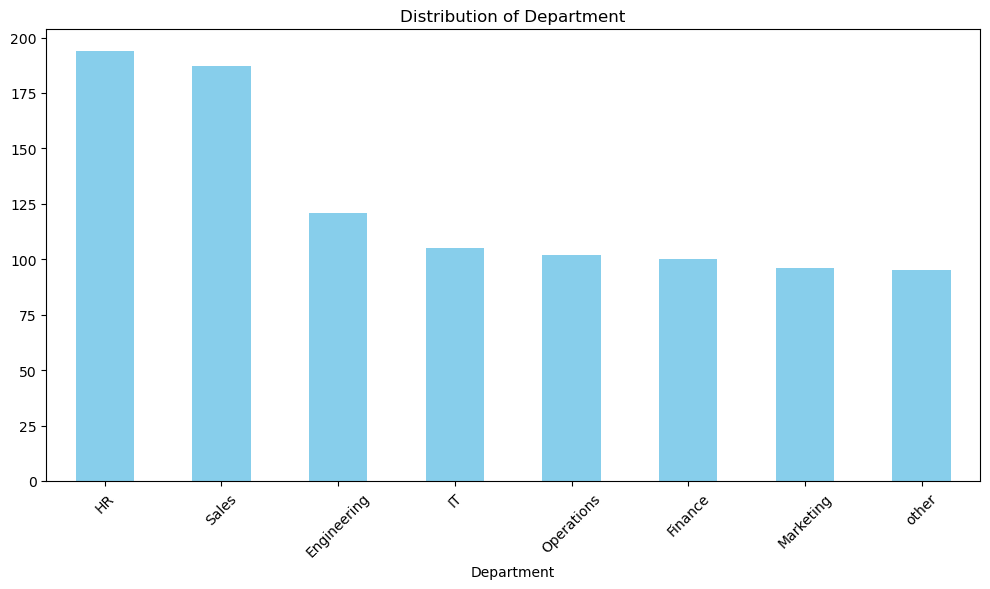


-- SalaryBand --
SalaryBand
High         204
Low          203
Medium       197
other        108
Band-B       107
Very High     92
Band-A        89
Name: count, dtype: int64


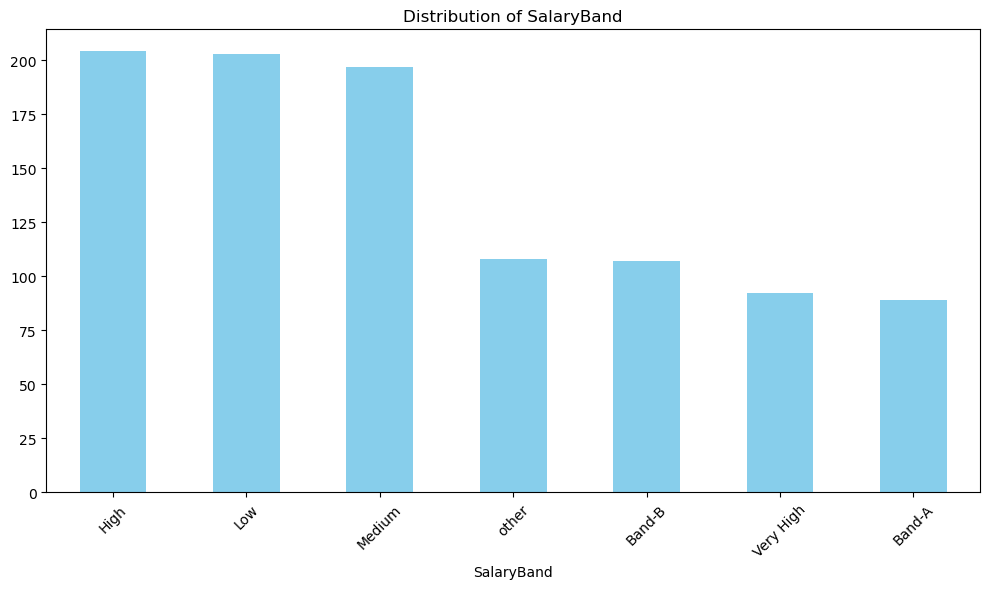


-- JobRole --
JobRole
Manager           200
Analyst           193
Engineer          110
Associate         102
Senior Analyst    101
Lead              100
other              98
Director           96
Name: count, dtype: int64


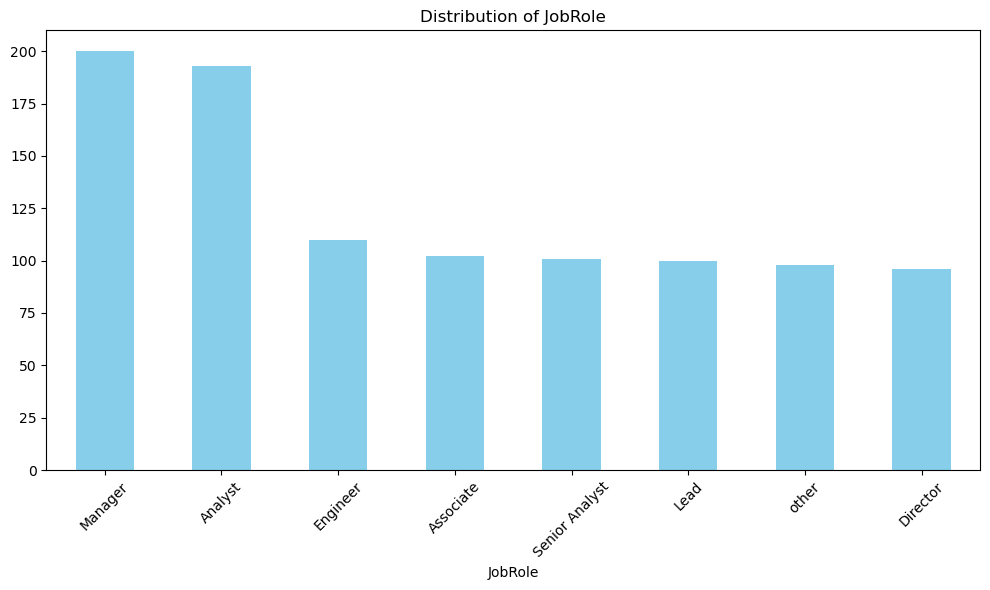


-- Gender --
Gender
Male      412
Female    396
Other     104
other      88
Name: count, dtype: int64


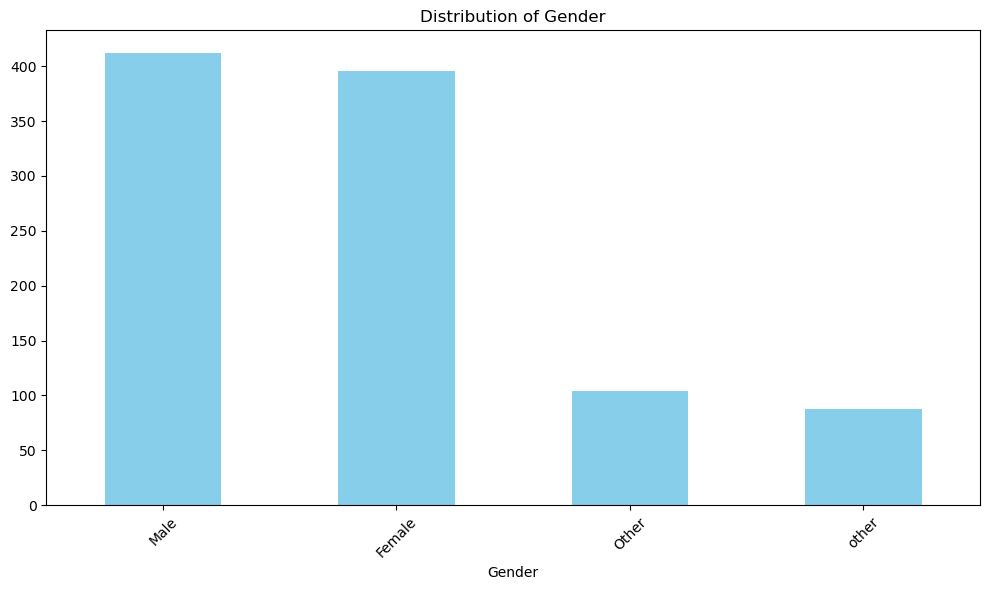


-- Attrition --
Attrition
No     726
Yes    274
Name: count, dtype: int64


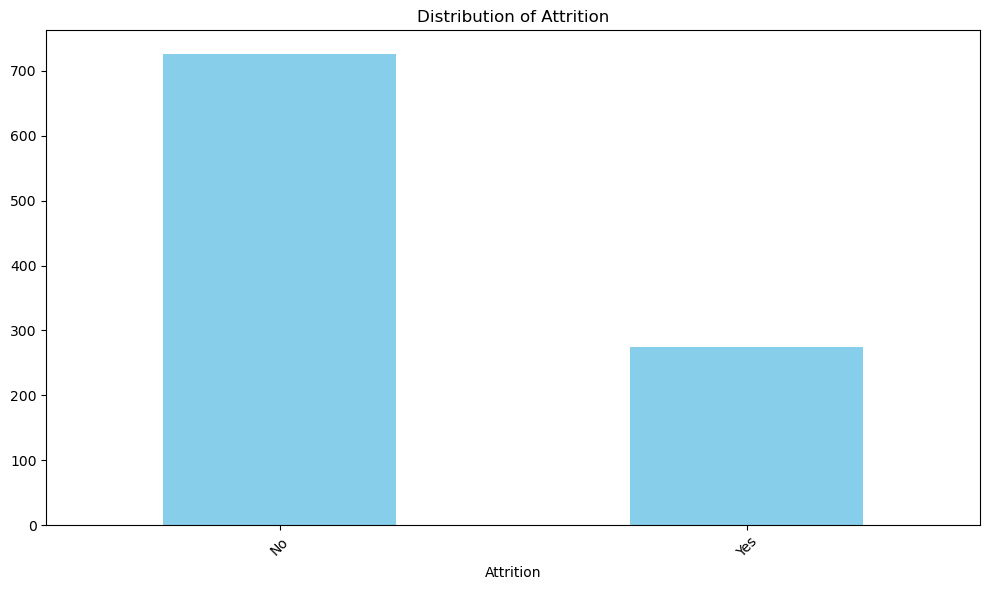

In [206]:
print("\n==  CATEGORICAL VARIABLES  ==\n")
categorical_cols = ["Department","SalaryBand", "JobRole", "Gender", "Attrition"]

for col in categorical_cols:
    print(f"\n-- {col} --")
    print(df[col].value_counts())


    #VISUALIZATION

    plt.figure(figsize=(10,6))
    df[col].value_counts().plot(kind="bar",color="skyblue")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()




In [207]:
df.columns

Index(['EmployeeID', 'Age', 'Department', 'SalaryBand', 'JobRole', 'Gender',
       'YearsAtCompany', 'PerformanceScore', 'MonthlyIncome', 'Attrition'],
      dtype='object')


--- Age ---
Mean: 41.11
Median: 41.11
Std Dev: 12.69
Min: 5.00
Max: 99.00


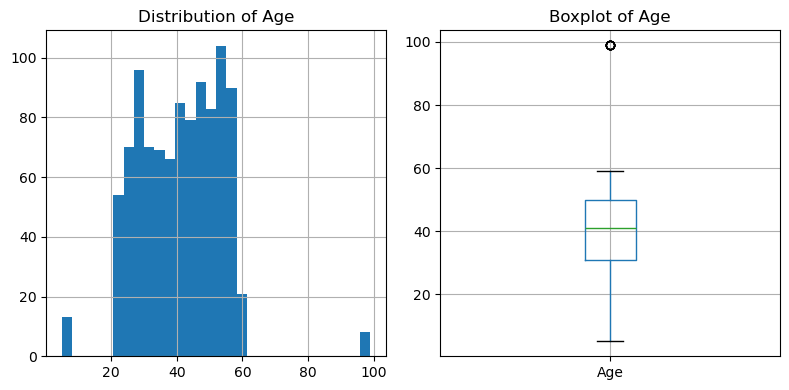


--- YearsAtCompany ---
Mean: 17.44
Median: 17.44
Std Dev: 9.85
Min: -1.00
Max: 35.00


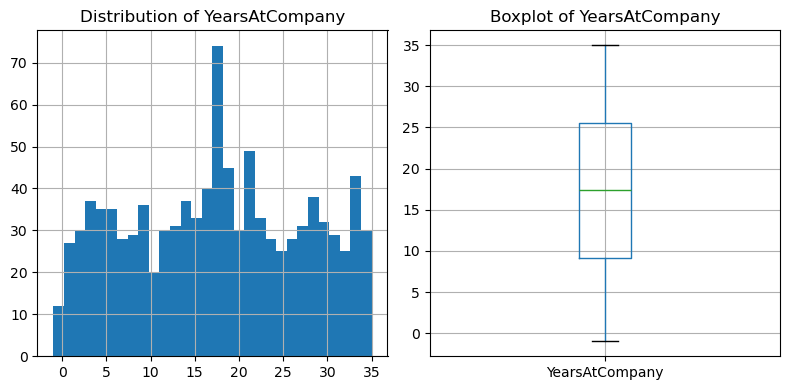


--- PerformanceScore ---
Mean: 4.26
Median: 3.10
Std Dev: 10.95
Min: -1.00
Max: 99.00


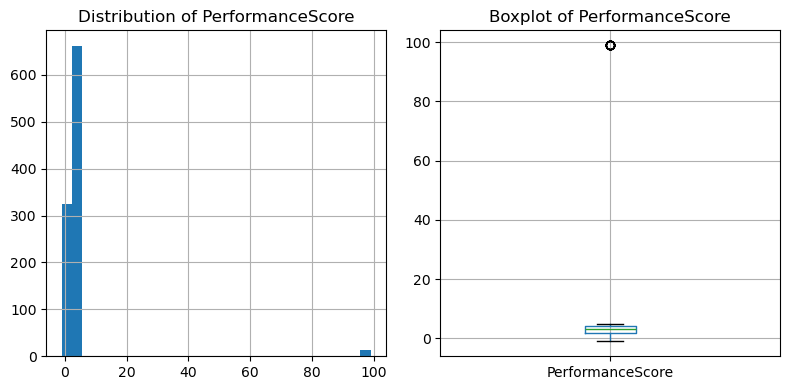


--- MonthlyIncome ---
Mean: 83763.69
Median: 86346.16
Std Dev: 38747.83
Min: 0.00
Max: 149940.71


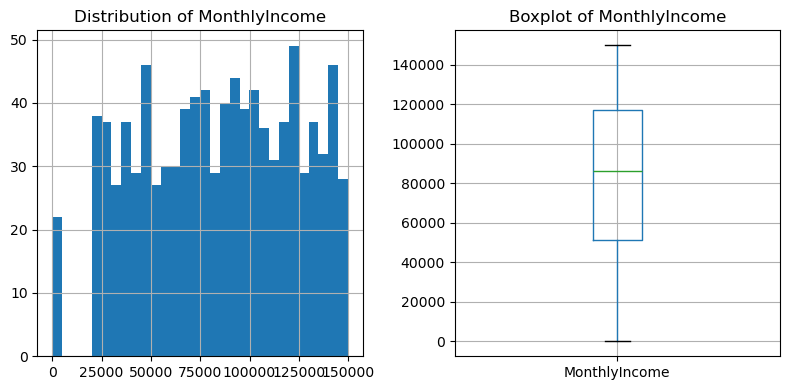

In [208]:


numerical_cols = [
    "Age","YearsAtCompany","PerformanceScore","MonthlyIncome"
    
]

for col in numerical_cols:

    df[col] = pd.to_numeric(df[col], errors='coerce')

    print(f"\n--- {col} ---")
    print(f"Mean: {df[col].mean():.2f}")
    print(f"Median: {df[col].median():.2f}")
    print(f"Std Dev: {df[col].std():.2f}")
    print(f"Min: {df[col].min():.2f}")
    print(f"Max: {df[col].max():.2f}")

    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    df[col].hist(bins=30)
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    df.boxplot(column=col)
    plt.title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

In [209]:
df.columns

Index(['EmployeeID', 'Age', 'Department', 'SalaryBand', 'JobRole', 'Gender',
       'YearsAtCompany', 'PerformanceScore', 'MonthlyIncome', 'Attrition'],
      dtype='object')

             MonthlyIncome        Age  Employee Count
Department                                           
Engineering   86115.674661  40.148760             121
Finance       75431.572917  41.450000             100
HR            85116.596044  40.503944             194
IT            82825.747800  41.508926             105
Marketing     88546.901368  42.001138              96
Operations    85554.067959  41.229776             102
Sales         82118.940552  40.980947             187
other         84165.273936  41.990624              95


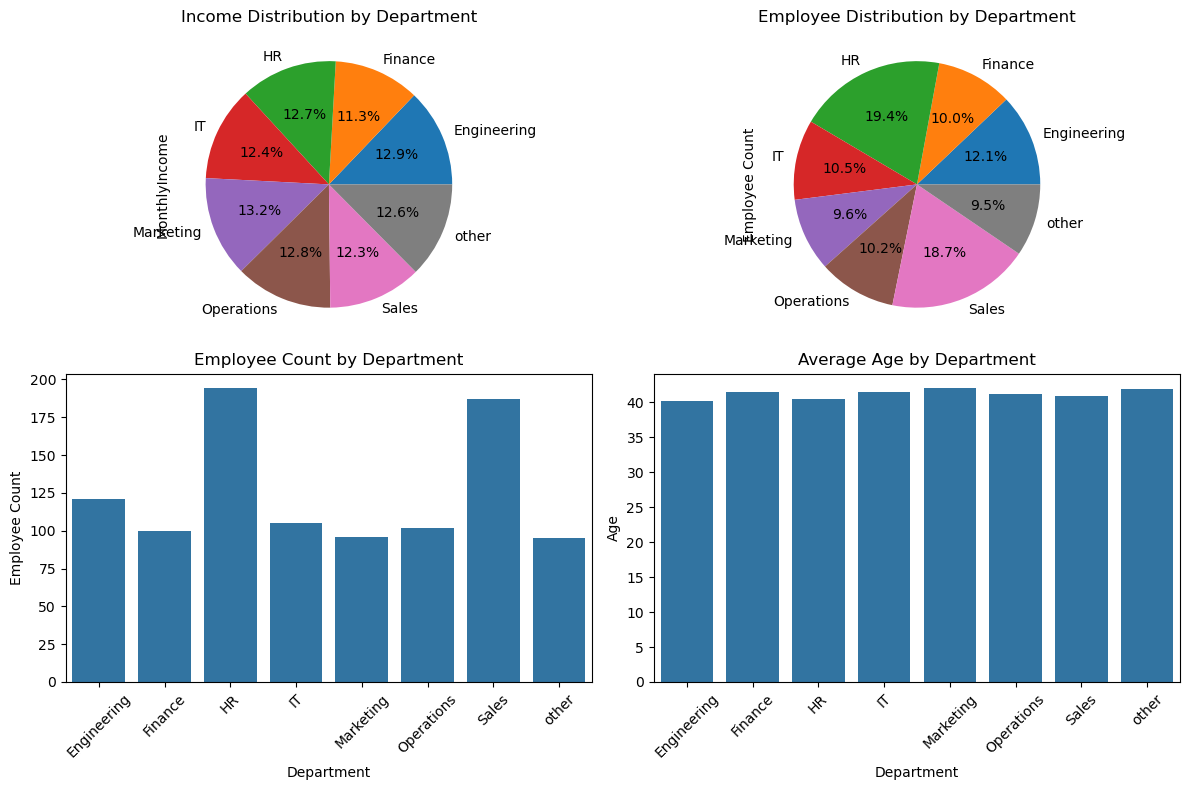

In [210]:
department_performance = df.groupby('Department').agg({
    'MonthlyIncome': 'mean',
    'Age': 'mean',
    'EmployeeID': 'count'
}).rename(columns={
    'EmployeeID': 'Employee Count'
})

print(department_performance)

plt.figure(figsize=(12,8))

# Average Monthly Income
plt.subplot(2,2,1)
department_performance['MonthlyIncome'].plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.title('Income Distribution by Department')

# Employee Count
plt.subplot(2,2,2)
department_performance['Employee Count'].plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.title('Employee Distribution by Department')

# Employee Count Bar Chart
plt.subplot(2,2,3)
sns.barplot(
    x=department_performance.index,
    y=department_performance['Employee Count']
)
plt.title('Employee Count by Department')
plt.xticks(rotation=45)

# Average Age
plt.subplot(2,2,4)
sns.barplot(
    x=department_performance.index,
    y=department_performance['Age']
)
plt.title('Average Age by Department')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

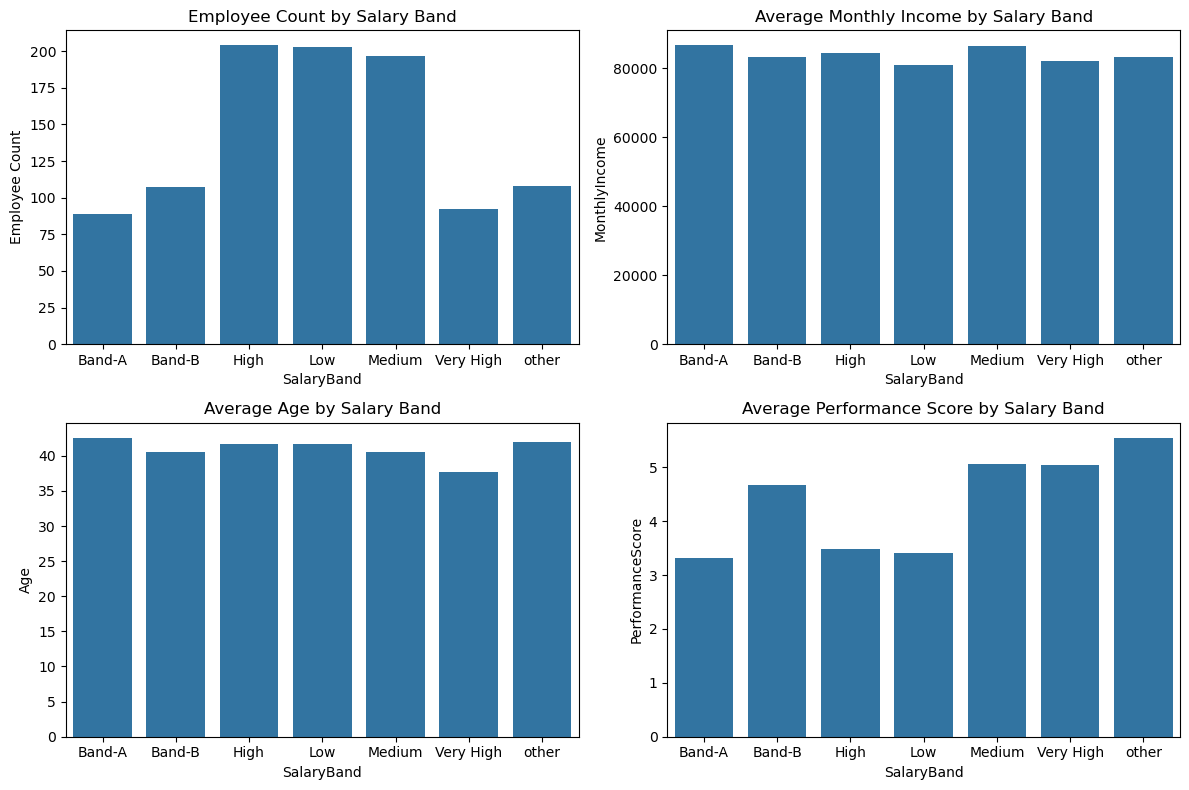

In [212]:
plt.figure(figsize=(12, 8))

# Employee Count
plt.subplot(2, 2, 1)
sns.barplot(
    x=salaryband_analysis.index,
    y=salaryband_analysis['Employee Count']
)
plt.title('Employee Count by Salary Band')

# Average Monthly Income
plt.subplot(2, 2, 2)
sns.barplot(
    x=salaryband_analysis.index,
    y=salaryband_analysis['MonthlyIncome']
)
plt.title('Average Monthly Income by Salary Band')

# Average Age
plt.subplot(2, 2, 3)
sns.barplot(
    x=salaryband_analysis.index,
    y=salaryband_analysis['Age']
)
plt.title('Average Age by Salary Band')

# Average Performance Score
plt.subplot(2, 2, 4)
sns.barplot(
    x=salaryband_analysis.index,
    y=salaryband_analysis['PerformanceScore']
)
plt.title('Average Performance Score by Salary Band')

plt.tight_layout()
plt.show()

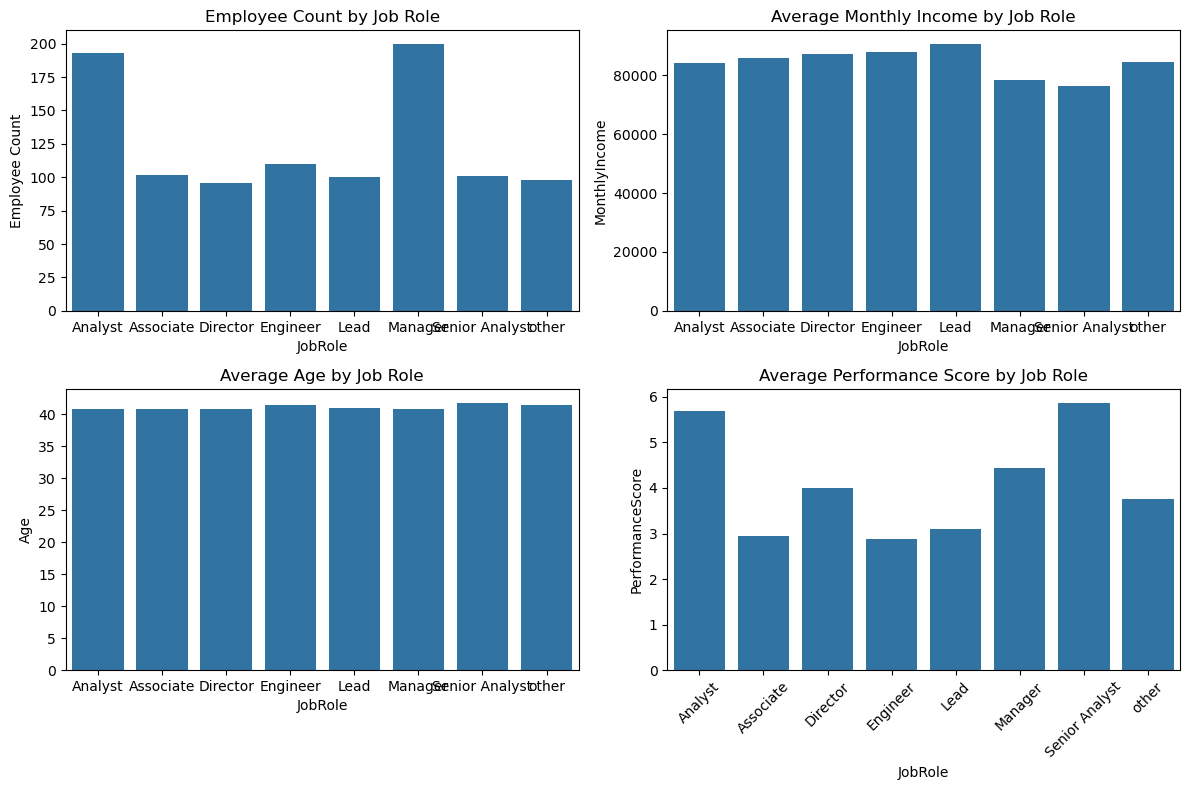

In [215]:
jobrole_analysis = df.groupby("JobRole").agg({
    "MonthlyIncome": "mean",
    "Age": "mean",
    "PerformanceScore": "mean",
    "EmployeeID": "count"
}).rename(columns={"EmployeeID": "Employee Count"})


plt.figure(figsize=(12, 8))

# Employee Count
plt.subplot(2, 2, 1)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['Employee Count']
)
plt.title('Employee Count by Job Role')

# Average Monthly Income
plt.subplot(2, 2, 2)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['MonthlyIncome']
)
plt.title('Average Monthly Income by Job Role')

# Average Age
plt.subplot(2, 2, 3)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['Age']
)
plt.title('Average Age by Job Role')

# Average Performance Score
plt.subplot(2, 2, 4)
sns.barplot(
    x=jobrole_analysis.index,
    y=jobrole_analysis['PerformanceScore']
)
plt.title('Average Performance Score by Job Role')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

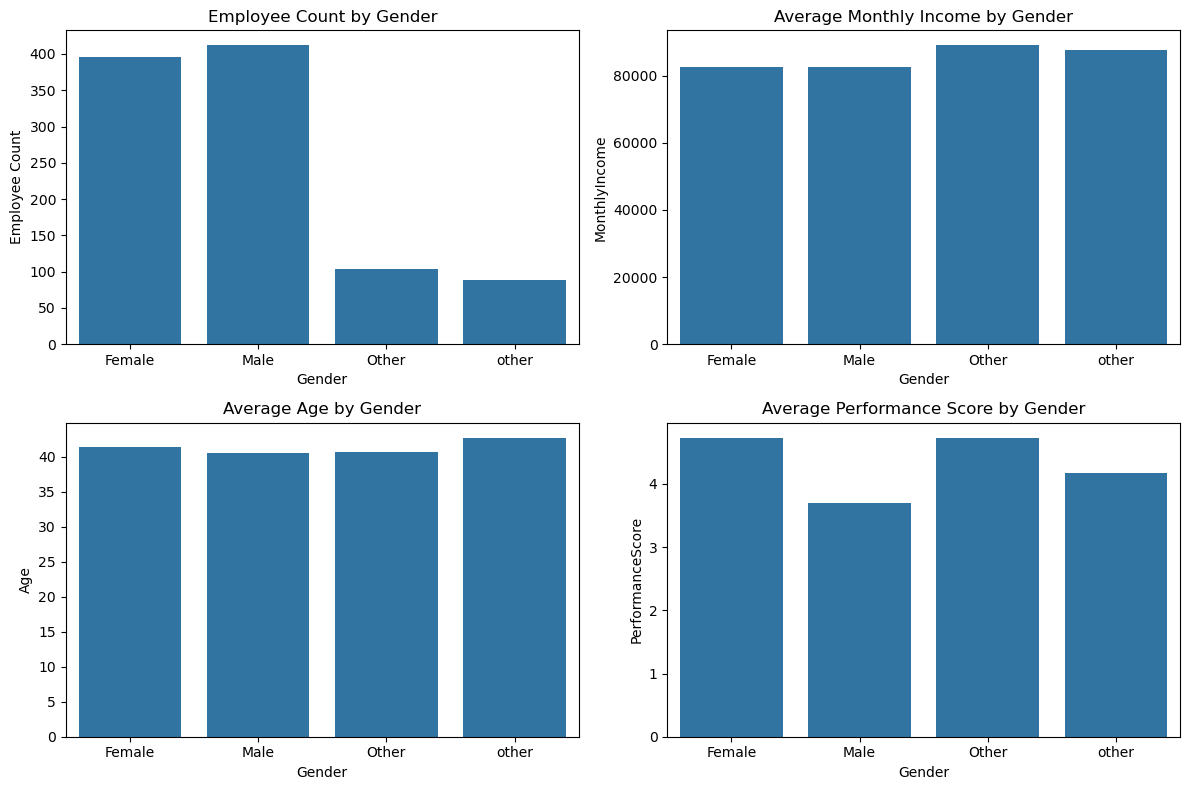

In [216]:
gender_analysis = df.groupby("Gender").agg({
    "MonthlyIncome": "mean",
    "Age": "mean",
    "PerformanceScore": "mean",
    "EmployeeID": "count"
}).rename(columns={"EmployeeID": "Employee Count"})


plt.figure(figsize=(12, 8))

# Employee Count
plt.subplot(2, 2, 1)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['Employee Count']
)
plt.title('Employee Count by Gender')

# Average Monthly Income
plt.subplot(2, 2, 2)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['MonthlyIncome']
)
plt.title('Average Monthly Income by Gender')

# Average Age
plt.subplot(2, 2, 3)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['Age']
)
plt.title('Average Age by Gender')

# Average Performance Score
plt.subplot(2, 2, 4)
sns.barplot(
    x=gender_analysis.index,
    y=gender_analysis['PerformanceScore']
)
plt.title('Average Performance Score by Gender')

plt.tight_layout()
plt.show()